we are going to visualise quantum superposition using Qiskit Aer. The goal is to see how a qubit can move from a definite zero state into a superposition, how measurement produces either zero or one, and how repeated simulation reveals the underlying probability distribution.

In [3]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

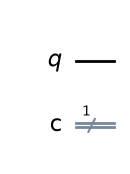

In [4]:
circuit = QuantumCircuit(1, 1)

circuit.draw("mpl")

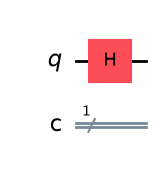

In [5]:
circuit.h(0)

circuit.draw("mpl")

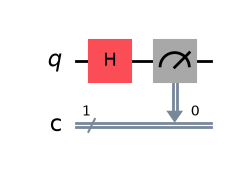

In [6]:
circuit.measure(0, 0)

circuit.draw("mpl")

In [7]:
simulator = AerSimulator()

In [9]:
single_result = simulator.run(
    circuit,
    shots=1
).result()

single_counts = single_result.get_counts()

print(single_counts)

{'1': 1}


In [10]:
result = simulator.run(
    circuit,
    shots=1000
).result()

counts = result.get_counts()

print(counts)

{'0': 505, '1': 495}


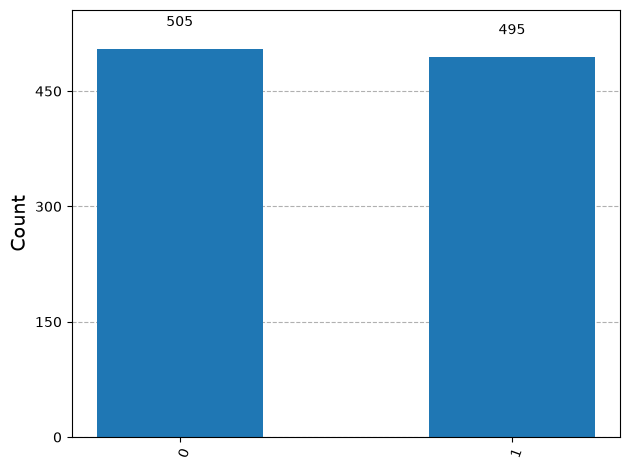

In [11]:
plot_histogram(counts)

In [12]:
total_shots = sum(counts.values())

probability_0 = counts.get("0", 0) / total_shots
probability_1 = counts.get("1", 0) / total_shots

print(f"Probability of |0>: {probability_0:.2%}")
print(f"Probability of |1>: {probability_1:.2%}")

Probability of |0>: 50.50%
Probability of |1>: 49.50%


In [13]:
shots_list = [10, 100, 1000, 10000]

results = []

for shots in shots_list:
    result = simulator.run(circuit, shots=shots).result()
    results.append(result.get_counts())

results

[{'0': 4, '1': 6},
 {'0': 52, '1': 48},
 {'0': 498, '1': 502},
 {'0': 5076, '1': 4924}]

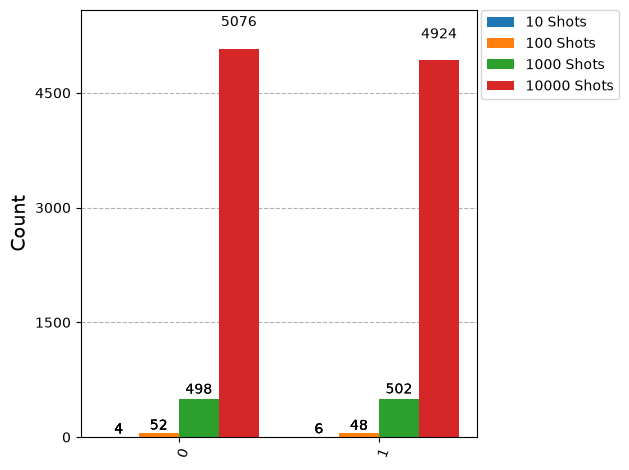

In [14]:
plot_histogram(
    results,
    legend=["10 Shots", "100 Shots", "1000 Shots", "10000 Shots"]
)